# Praktikum Uji Validitas dan Reliabilitas Instrumen
**Mata Kuliah:** Probabilitas dan Statistika  
**Topik:** Penggunaan AI pada Tugas atau Projek Kuliah – Kelas 3 TI A  
**Data:** Respons Gabungan 3 TI A – Versi Baru – 29 Butir  
**Tools:** Python di Google Colab

Notebook ini disiapkan berdasarkan file Excel terbaru yang diberikan. Struktur data yang terdeteksi:
- 39 responden kelas 3 TI A
- 29 butir pernyataan
- 5 dimensi: Penggunaan AI pada tugas atau projek kuliah (7 butir), Aspek psikologis penggunaan AI pada tugas atau projek kuliah (7 butir), Kebiasaan penggunaan teknologi digital (6 butir), Prokrastinasi akademik (4 butir), dan Respons emosional (5 butir).
- Dua kolom awal adalah Cap waktu dan Kelas; analisis dimulai dari kolom ketiga.

**Cara menggunakan:** Buka notebook di Google Colab, jalankan setiap sel secara berurutan, lalu unggah file Excel terbaru `Respons Gabungan 3 TI A - Versi Baru - 29 Butir.xlsx` saat diminta. Jangan mengubah jawaban responden.

## 1. Persiapan dan impor library

In [1]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from google.colab import files
from IPython.display import display

print("Library berhasil diimpor!")

Library berhasil diimpor!


## 2. Unggah file Excel terbaru

In [2]:
up = files.upload()
nama_file = list(up.keys())[0]
print("File terbaca:", nama_file)

Saving Respons Gabungan 3 TI A - Versi Baru - 29 Butir.xlsx to Respons Gabungan 3 TI A - Versi Baru - 29 Butir.xlsx
File terbaca: Respons Gabungan 3 TI A - Versi Baru - 29 Butir.xlsx


## 3. Membaca data dan memisahkan butir
File terbaru memiliki dua kolom identitas di awal: `Cap waktu` dan `Kelas`. Oleh karena itu, analisis dimulai dari kolom indeks 2. Program juga memfilter kelas 3 TI A jika kolom `Kelas` tersedia.

In [3]:
JUMLAH_KOLOM_DEMOGRAFI = 2

df_asli = pd.read_excel(nama_file)

if "Kelas" in df_asli.columns:
    df = df_asli[df_asli["Kelas"].astype(str).str.strip().str.upper() == "3 TI A"].copy()
else:
    df = df_asli.copy()

butir = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:].copy()

print("Jumlah responden:", len(df))
print("Jumlah butir:", butir.shape[1])
print("Jumlah data kosong:", int(butir.isna().sum().sum()))
print("Nama kolom identitas:", df.columns[:JUMLAH_KOLOM_DEMOGRAFI].tolist())
display(df.head())

Jumlah responden: 39
Jumlah butir: 29
Jumlah data kosong: 0
Nama kolom identitas: ['Cap waktu', 'Kelas']


,Cap waktu,Kelas,Penggunaan AI pada tugas atau projek kuliah [AI1. Saya menggunakan AI ketika mengerjakan tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI2. Saya menggunakan AI untuk memahami persoalan dalam tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI3. Saya menggunakan AI untuk mencari ide pengerjaan tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI4. Saya menggunakan AI untuk menyusun langkah penyelesaian tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI5. Saya menggunakan AI untuk memperoleh contoh penyelesaian tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI6. Saya menggunakan AI untuk mengembangkan jawaban tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI7. Saya menggunakan AI untuk meninjau jawaban tugas kuliah sebelum dikumpulkan.],Aspek psikologis penggunaan AI pada tugas atau projek kuliah [PS1. Saya merasa membutuhkan bantuan AI untuk mulai mengerjakan tugas kuliah.],...,Kebiasaan penggunaan teknologi digital [TD6. Saya menggunakan jawaban AI dalam tugas kuliah setelah membacanya sekilas.],Prokrastinasi akademik [PA1. Saya menunda memulai tugas kuliah hingga mendekati batas pengumpulan.],Prokrastinasi akademik [PA2. Saya memulai pengerjaan tugas kuliah lebih lambat daripada waktu yang saya rencanakan.],Prokrastinasi akademik [PA3. Saya menunda melanjutkan tugas kuliah yang sudah saya mulai.],Prokrastinasi akademik [PA4. Saya menyelesaikan tugas kuliah pada saat waktu pengumpulan hampir berakhir.],Respons emosional [RE1. Saya merasa tertekan ketika waktu pengerjaan tugas menjadi singkat akibat menunda.],Respons emosional [RE2. Saya merasa cemas ketika tugas yang saya tunda mendekati batas pengumpulan.],Respons emosional [RE3. Saya merasa panik ketika beberapa tugas yang saya tunda harus segera dikumpulkan.],Respons emosional [RE4. Saya merasa gelisah ketika memikirkan tugas yang pengerjaannya saya tunda.],Respons emosional [RE5. Saya merasa kewalahan menghadapi tugas yang menumpuk akibat penundaan.]
0,2026-11-13 20:54:44.060,3 TI A,Sangat Tidak Setuju (STS),Tidak Setuju (TS),Setuju (S),Sangat Setuju (SS),Setuju (S),Tidak Setuju (TS),Sangat Tidak Setuju (STS),Sangat Tidak Setuju (STS),...,Tidak Setuju (TS),Sangat Tidak Setuju (STS),Tidak Setuju (TS),Setuju (S),Sangat Setuju (SS),Sangat Tidak Setuju (STS),Tidak Setuju (TS),Setuju (S),Sangat Setuju (SS),Setuju (S)
1,2026-11-13 20:55:17.425,3 TI A,Sangat Tidak Setuju (STS),Tidak Setuju (TS),Sangat Tidak Setuju (STS),Sangat Setuju (SS),Sangat Setuju (SS),Setuju (S),Sangat Tidak Setuju (STS),Sangat Tidak Setuju (STS),...,Sangat Tidak Setuju (STS),Setuju (S),Setuju (S),Setuju (S),Sangat Tidak Setuju (STS),Sangat Setuju (SS),Sangat Tidak Setuju (STS),Sangat Tidak Setuju (STS),Sangat Setuju (SS),Setuju (S)
2,2026-11-13 20:55:22.077,3 TI A,Sangat Tidak Setuju (STS),Tidak Setuju (TS),Sangat Tidak Setuju (STS),Tidak Setuju (TS),Tidak Setuju (TS),Tidak Setuju (TS),Sangat Tidak Setuju (STS),Tidak Setuju (TS),...,Tidak Setuju (TS),Sangat Tidak Setuju (STS),Tidak Setuju (TS),Tidak Setuju (TS),Sangat Tidak Setuju (STS),Sangat Tidak Setuju (STS),Tidak Setuju (TS),Tidak Setuju (TS),Sangat Tidak Setuju (STS),Tidak Setuju (TS)
3,2026-11-13 20:55:28.868,3 TI A,Sangat Setuju (SS),Setuju (S),Tidak Setuju (TS),Sangat Tidak Setuju (STS),Tidak Setuju (TS),Setuju (S),Sangat Setuju (SS),Sangat Tidak Setuju (STS),...,Sangat Setuju (SS),Sangat Tidak Setuju (STS),Tidak Setuju (TS),Sangat Setuju (SS),Setuju (S),Sangat Tidak Setuju (STS),Tidak Setuju (TS),Setuju (S),Sangat Setuju (SS),Setuju (S)
4,2026-11-13 20:55:38.165,3 TI A,Sangat Setuju (SS),Setuju (S),Tidak Setuju (TS),Sangat Tidak Setuju (STS),Tidak Setuju (TS),Setuju (S),Sangat Setuju (SS),Sangat Setuju (SS),...,Setuju (S),Sangat Setuju (SS),Setuju (S),Tidak Setuju (TS),Sangat Tidak Setuju (STS),Sangat Setuju (SS),Setuju (S),Tidak Setuju (TS),Sangat Tidak Setuju (STS),Tidak Setuju (TS)


## 4. Mengubah jawaban Likert menjadi angka
Pemetaan skala sesuai modul: STS=1, TS=2, Netral=3, Setuju=4, dan SS=5. Program merapikan spasi sebelum mengubah jawaban menjadi angka.

In [4]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5
}

butir_bersih = butir.apply(
    lambda kolom: kolom.map(
        lambda v: re.sub(r"\s+", " ", v.strip()) if isinstance(v, str) else v
    )
)
num = butir_bersih.replace(skala).apply(pd.to_numeric, errors="coerce")

gagal = int(num.isna().sum().sum())
print("Sel yang gagal dikonversi atau kosong:", gagal)

if gagal > 0:
    raise ValueError(
        "Masih ada jawaban kosong atau label yang tidak dikenali. "
        "Periksa label jawaban di Excel dan samakan dengan kamus skala."
    )

display(num.head())

Sel yang gagal dikonversi atau kosong: 0


/tmp/ipykernel_1141/2910652288.py:14: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = butir_bersih.replace(skala).apply(pd.to_numeric, errors="coerce")


,Penggunaan AI pada tugas atau projek kuliah [AI1. Saya menggunakan AI ketika mengerjakan tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI2. Saya menggunakan AI untuk memahami persoalan dalam tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI3. Saya menggunakan AI untuk mencari ide pengerjaan tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI4. Saya menggunakan AI untuk menyusun langkah penyelesaian tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI5. Saya menggunakan AI untuk memperoleh contoh penyelesaian tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI6. Saya menggunakan AI untuk mengembangkan jawaban tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI7. Saya menggunakan AI untuk meninjau jawaban tugas kuliah sebelum dikumpulkan.],Aspek psikologis penggunaan AI pada tugas atau projek kuliah [PS1. Saya merasa membutuhkan bantuan AI untuk mulai mengerjakan tugas kuliah.],Aspek psikologis penggunaan AI pada tugas atau projek kuliah [PS2. Saya merasa perlu memperoleh saran AI sebelum menentukan langkah pengerjaan tugas kuliah.],Aspek psikologis penggunaan AI pada tugas atau projek kuliah [PS3. Saya merasa lebih yakin terhadap jawaban tugas setelah memperoleh konfirmasi dari AI.],...,Kebiasaan penggunaan teknologi digital [TD6. Saya menggunakan jawaban AI dalam tugas kuliah setelah membacanya sekilas.],Prokrastinasi akademik [PA1. Saya menunda memulai tugas kuliah hingga mendekati batas pengumpulan.],Prokrastinasi akademik [PA2. Saya memulai pengerjaan tugas kuliah lebih lambat daripada waktu yang saya rencanakan.],Prokrastinasi akademik [PA3. Saya menunda melanjutkan tugas kuliah yang sudah saya mulai.],Prokrastinasi akademik [PA4. Saya menyelesaikan tugas kuliah pada saat waktu pengumpulan hampir berakhir.],Respons emosional [RE1. Saya merasa tertekan ketika waktu pengerjaan tugas menjadi singkat akibat menunda.],Respons emosional [RE2. Saya merasa cemas ketika tugas yang saya tunda mendekati batas pengumpulan.],Respons emosional [RE3. Saya merasa panik ketika beberapa tugas yang saya tunda harus segera dikumpulkan.],Respons emosional [RE4. Saya merasa gelisah ketika memikirkan tugas yang pengerjaannya saya tunda.],Respons emosional [RE5. Saya merasa kewalahan menghadapi tugas yang menumpuk akibat penundaan.]
0,1,2,4,5,4,2,1,1,2,4,...,2,1,2,4,5,1,2,4,5,4
1,1,2,1,5,5,4,1,1,2,1,...,1,4,4,4,1,5,1,1,5,4
2,1,2,1,2,2,2,1,2,2,1,...,2,1,2,2,1,1,2,2,1,2
3,5,4,2,1,2,4,5,1,2,4,...,5,1,2,5,4,1,2,4,5,4
4,5,4,2,1,2,4,5,5,4,2,...,4,5,4,2,1,5,4,2,1,2


## 5. Mengelompokkan butir berdasarkan dimensi
Nama dimensi diambil dari teks sebelum tanda kurung siku `[`. Contoh format judul kolom: `Nama Dimensi [kode dan teks pernyataan]`.

In [5]:
dimensi = {}

for kolom in butir.columns:
    cocok = re.match(r"^(.*?)\s*\[", str(kolom))
    if cocok is None:
        raise ValueError(
            f"Format judul kolom tidak sesuai: {kolom}. "
            "Judul harus memiliki nama dimensi diikuti tanda [."
        )
    nama_dimensi = cocok.group(1).strip()
    dimensi.setdefault(nama_dimensi, []).append(kolom)

print("Jumlah dimensi:", len(dimensi))
for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")

print("Total butir yang dikelompokkan:", sum(len(v) for v in dimensi.values()))

Jumlah dimensi: 5
Penggunaan AI pada tugas atau projek kuliah: 7 butir
Aspek psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik: 4 butir
Respons emosional: 5 butir
Total butir yang dikelompokkan: 29


## 6. Uji validitas (korelasi Pearson butir-total)
Setiap butir dikorelasikan dengan total skor pada dimensinya. Keputusan utama mengikuti modul: butir valid jika **r hitung > r tabel**, dengan α=0,05 (dua sisi) dan df=n−2. `Corrected r` merupakan korelasi butir dengan total tanpa butir itu sendiri dan ditampilkan sebagai pemeriksaan tambahan.

In [6]:
n = len(num)
if n <= 2:
    raise ValueError("Jumlah responden harus lebih dari 2.")

df_bebas = n - 2
t_kritis = stats.t.ppf(0.975, df_bebas)
r_tabel = t_kritis / np.sqrt(df_bebas + t_kritis**2)

print(f"Jumlah responden (n) = {n}")
print(f"Derajat bebas (df) = {df_bebas}")
print(f"r tabel (α=0,05; dua sisi) = {r_tabel:.3f}")

hasil_validitas = []

for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)

    for i, kolom in enumerate(daftar, 1):
        if x[kolom].nunique() < 2 or total.nunique() < 2:
            r_hitung, p_value = np.nan, np.nan
        else:
            r_hitung, p_value = stats.pearsonr(x[kolom], total)

        total_koreksi = total - x[kolom]
        if x[kolom].nunique() < 2 or total_koreksi.nunique() < 2:
            corrected_r = np.nan
        else:
            corrected_r, _ = stats.pearsonr(x[kolom], total_koreksi)

        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "Pernyataan": kolom,
            "r hitung": round(r_hitung, 3) if pd.notna(r_hitung) else np.nan,
            "Corrected r": round(corrected_r, 3) if pd.notna(corrected_r) else np.nan,
            "p-value": round(p_value, 4) if pd.notna(p_value) else np.nan,
            "Keterangan": "Valid" if pd.notna(r_hitung) and r_hitung > r_tabel else "Tidak valid",
            "Corrected r ≥ 0,30": "Ya" if pd.notna(corrected_r) and corrected_r >= 0.30 else "Tidak"
        })

tabel_validitas = pd.DataFrame(hasil_validitas)
display(tabel_validitas)

Jumlah responden (n) = 39
Derajat bebas (df) = 37
r tabel (α=0,05; dua sisi) = 0.316


,Dimensi,Butir,Pernyataan,r hitung,Corrected r,p-value,Keterangan,"Corrected r ≥ 0,30"
0,Penggunaan AI pada tugas atau projek kuliah,B1,Penggunaan AI pada tugas atau projek kuliah [A...,0.662,0.424,0.0000,Valid,Ya
1,Penggunaan AI pada tugas atau projek kuliah,B2,Penggunaan AI pada tugas atau projek kuliah [A...,0.514,0.347,0.0008,Valid,Ya
2,Penggunaan AI pada tugas atau projek kuliah,B3,Penggunaan AI pada tugas atau projek kuliah [A...,0.678,0.517,0.0000,Valid,Ya
3,Penggunaan AI pada tugas atau projek kuliah,B4,Penggunaan AI pada tugas atau projek kuliah [A...,0.238,-0.030,0.1454,Tidak valid,Tidak
4,Penggunaan AI pada tugas atau projek kuliah,B5,Penggunaan AI pada tugas atau projek kuliah [A...,0.539,0.311,0.0004,Valid,Ya
5,Penggunaan AI pada tugas atau projek kuliah,B6,Penggunaan AI pada tugas atau projek kuliah [A...,0.493,0.295,0.0014,Valid,Tidak
6,Penggunaan AI pada tugas atau projek kuliah,B7,Penggunaan AI pada tugas atau projek kuliah [A...,0.776,0.618,0.0000,Valid,Ya
7,Aspek psikologis penggunaan AI pada tugas atau...,B1,Aspek psikologis penggunaan AI pada tugas atau...,0.494,0.150,0.0014,Valid,Tidak
8,Aspek psikologis penggunaan AI pada tugas atau...,B2,Aspek psikologis penggunaan AI pada tugas atau...,0.559,0.311,0.0002,Valid,Ya
9,Aspek psikologis penggunaan AI pada tugas atau...,B3,Aspek psikologis penggunaan AI pada tugas atau...,0.569,0.340,0.0002,Valid,Ya


### Ringkasan hasil uji validitas

In [7]:
jumlah_valid = int((tabel_validitas["Keterangan"] == "Valid").sum())
jumlah_tidak_valid = int((tabel_validitas["Keterangan"] == "Tidak valid").sum())
jumlah_corrected_lolos = int((tabel_validitas["Corrected r ≥ 0,30"] == "Ya").sum())

print(f"Butir valid berdasarkan r hitung > r tabel: {jumlah_valid}")
print(f"Butir tidak valid berdasarkan r hitung > r tabel: {jumlah_tidak_valid}")
print(f"Butir dengan Corrected r ≥ 0,30: {jumlah_corrected_lolos}")

Butir valid berdasarkan r hitung > r tabel: 26
Butir tidak valid berdasarkan r hitung > r tabel: 3
Butir dengan Corrected r ≥ 0,30: 11


## 7. Uji reliabilitas (Cronbach's Alpha)
Cronbach's Alpha dihitung secara terpisah untuk setiap dimensi. Kategori sesuai modul: α≥0,90 sangat baik; 0,80–0,89 baik; 0,70–0,79 reliabel; dan α<0,70 tidak reliabel. Alpha jika butir dihapus dihitung untuk dimensi dengan lebih dari dua butir.

In [8]:
def cronbach_alpha(x):
    k = x.shape[1]
    if k < 2:
        return np.nan
    varians_total = x.sum(axis=1).var(ddof=1)
    if varians_total == 0:
        return np.nan
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / varians_total)

def kategori_alpha(a):
    if pd.isna(a):
        return "Tidak dapat dihitung"
    if a >= 0.90:
        return "Sangat baik"
    elif a >= 0.80:
        return "Baik"
    elif a >= 0.70:
        return "Reliabel"
    else:
        return "Tidak reliabel"

hasil_reliabilitas = []
hasil_alpha_dihapus = []

for nama, daftar in dimensi.items():
    x = num[daftar]
    alpha = cronbach_alpha(x)

    hasil_reliabilitas.append({
        "Dimensi": nama,
        "Jumlah butir": len(daftar),
        "Cronbach's alpha": round(alpha, 3) if pd.notna(alpha) else np.nan,
        "Kategori": kategori_alpha(alpha)
    })

    if len(daftar) > 2:
        for i, kolom in enumerate(daftar, 1):
            alpha_hapus = cronbach_alpha(x.drop(columns=kolom))
            hasil_alpha_dihapus.append({
                "Dimensi": nama,
                "Butir": f"B{i}",
                "Alpha jika dihapus": round(alpha_hapus, 3) if pd.notna(alpha_hapus) else np.nan
            })

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(hasil_alpha_dihapus)

print("Hasil Cronbach's Alpha per dimensi:")
display(tabel_reliabilitas)

print("Hasil Alpha jika butir dihapus:")
display(tabel_alpha_dihapus)

Hasil Cronbach's Alpha per dimensi:


,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,0.630,Tidak reliabel
1,Aspek psikologis penggunaan AI pada tugas atau...,7,0.421,Tidak reliabel
2,Kebiasaan penggunaan teknologi digital,6,0.308,Tidak reliabel
3,Prokrastinasi akademik,4,0.111,Tidak reliabel
4,Respons emosional,5,0.516,Tidak reliabel


Hasil Alpha jika butir dihapus:


,Dimensi,Butir,Alpha jika dihapus
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.563
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.595
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.540
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.706
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.603
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.607
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.488
7,Aspek psikologis penggunaan AI pada tugas atau...,B1,0.412
8,Aspek psikologis penggunaan AI pada tugas atau...,B2,0.322
9,Aspek psikologis penggunaan AI pada tugas atau...,B3,0.312


### Perbandingan alpha sebelum dan sesudah butir dihapus

In [9]:
if not tabel_alpha_dihapus.empty:
    perbandingan_alpha = tabel_alpha_dihapus.merge(
        tabel_reliabilitas[["Dimensi", "Cronbach's alpha"]],
        on="Dimensi",
        how="left"
    )
    perbandingan_alpha["Interpretasi"] = np.where(
        perbandingan_alpha["Alpha jika dihapus"] > perbandingan_alpha["Cronbach's alpha"],
        "Alpha meningkat jika butir dihapus; butir perlu ditinjau",
        "Alpha tidak meningkat jika butir dihapus"
    )
    display(perbandingan_alpha)
else:
    print("Tidak ada dimensi dengan lebih dari dua butir.")

,Dimensi,Butir,Alpha jika dihapus,Cronbach's alpha,Interpretasi
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.563,0.630,Alpha tidak meningkat jika butir dihapus
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.595,0.630,Alpha tidak meningkat jika butir dihapus
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.540,0.630,Alpha tidak meningkat jika butir dihapus
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.706,0.630,Alpha meningkat jika butir dihapus; butir perl...
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.603,0.630,Alpha tidak meningkat jika butir dihapus
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.607,0.630,Alpha tidak meningkat jika butir dihapus
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.488,0.630,Alpha tidak meningkat jika butir dihapus
7,Aspek psikologis penggunaan AI pada tugas atau...,B1,0.412,0.421,Alpha tidak meningkat jika butir dihapus
8,Aspek psikologis penggunaan AI pada tugas atau...,B2,0.322,0.421,Alpha tidak meningkat jika butir dihapus
9,Aspek psikologis penggunaan AI pada tugas atau...,B3,0.312,0.421,Alpha tidak meningkat jika butir dihapus


## 8. Analisis deskriptif per dimensi
Skor dimensi dihitung dengan menjumlahkan skor seluruh butir dalam dimensi untuk setiap responden. Statistik yang ditampilkan adalah mean, standar deviasi, skewness, kurtosis, skor minimum, dan skor maksimum.

In [10]:
hasil_deskriptif = []
skor_dimensi = {}

for nama, daftar in dimensi.items():
    skor = num[daftar].sum(axis=1)
    skor_dimensi[nama] = skor

    hasil_deskriptif.append({
        "Dimensi": nama,
        "Mean": round(skor.mean(), 3),
        "Standar deviasi": round(skor.std(ddof=1), 3),
        "Skewness": round(stats.skew(skor, bias=False), 3),
        "Kurtosis": round(stats.kurtosis(skor, bias=False), 3),
        "Skor minimum": int(skor.min()),
        "Skor maksimum": int(skor.max())
    })

tabel_deskriptif = pd.DataFrame(hasil_deskriptif)
display(tabel_deskriptif)

,Dimensi,Mean,Standar deviasi,Skewness,Kurtosis,Skor minimum,Skor maksimum
0,Penggunaan AI pada tugas atau projek kuliah,23.154,6.015,0.149,-0.549,10,33
1,Aspek psikologis penggunaan AI pada tugas atau...,22.333,4.975,0.339,-0.277,11,32
2,Kebiasaan penggunaan teknologi digital,17.718,4.353,-0.109,0.986,9,27
3,Prokrastinasi akademik,11.487,3.276,-0.075,0.354,4,18
4,Respons emosional,17.205,4.408,0.019,-0.973,8,25


### Grafik komposisi jawaban
Grafik berikut menampilkan frekuensi lima kategori jawaban pada setiap dimensi.

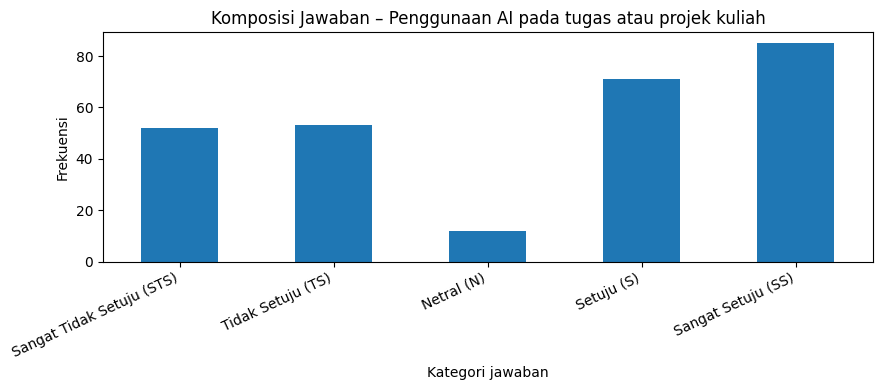

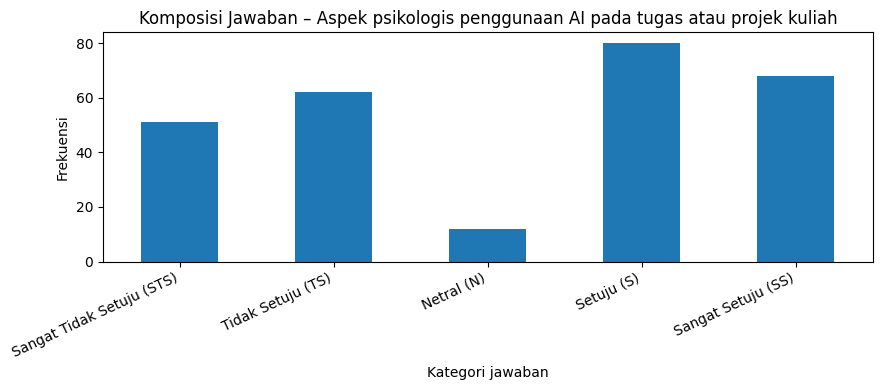

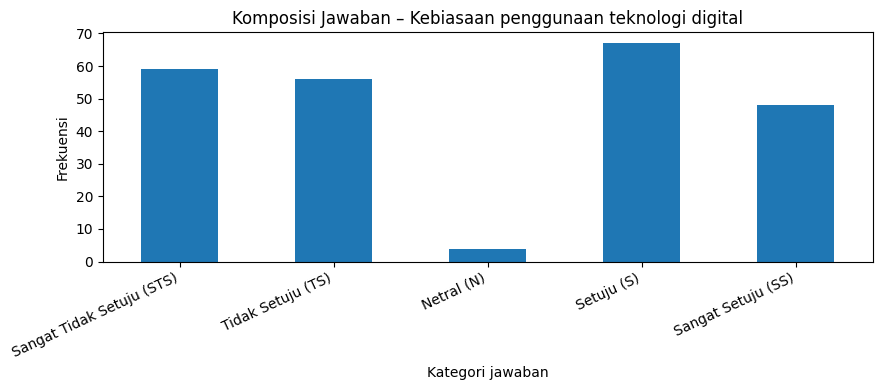

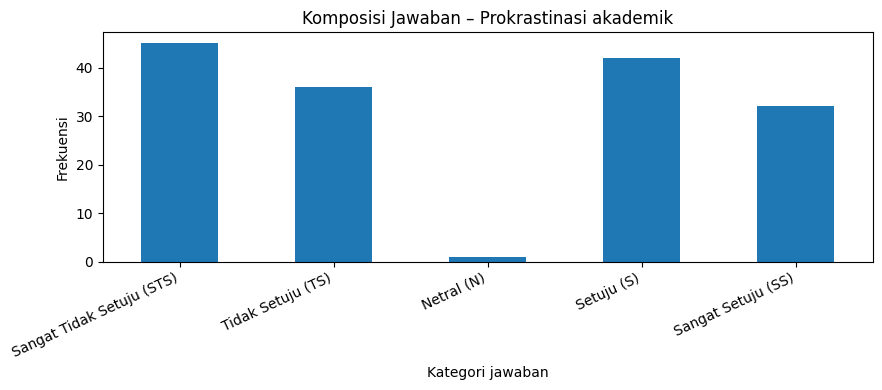

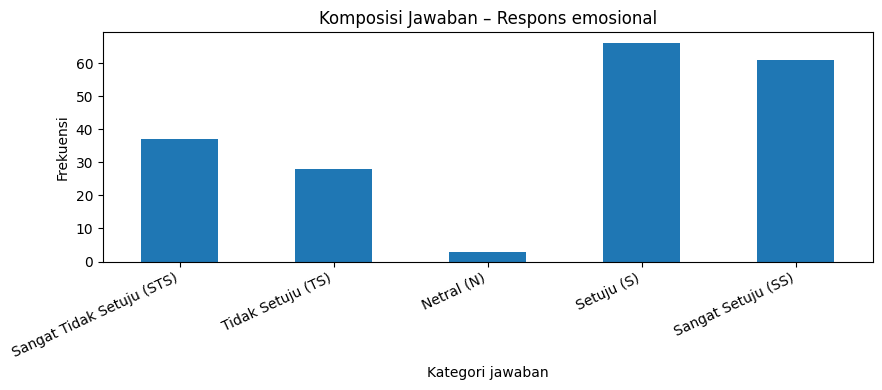

In [11]:
label_urut = [
    "Sangat Tidak Setuju (STS)",
    "Tidak Setuju (TS)",
    "Netral (N)",
    "Setuju (S)",
    "Sangat Setuju (SS)"
]

for nama, daftar in dimensi.items():
    frekuensi = (
        butir_bersih[daftar]
        .stack()
        .value_counts()
        .reindex(label_urut, fill_value=0)
    )

    plt.figure(figsize=(9, 4))
    frekuensi.plot(kind="bar")
    plt.title(f"Komposisi Jawaban – {nama}")
    plt.xlabel("Kategori jawaban")
    plt.ylabel("Frekuensi")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

## 9. Mengunduh hasil pengujian
File Excel keluaran berisi empat lembar: Validitas, Reliabilitas, Alpha jika dihapus, dan Deskriptif.

In [12]:
nama_output = "hasil_uji_validitas_reliabilitas_29_butir.xlsx"

with pd.ExcelWriter(nama_output) as writer:
    tabel_validitas.to_excel(writer, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(writer, sheet_name="Reliabilitas", index=False)
    tabel_alpha_dihapus.to_excel(writer, sheet_name="Alpha jika dihapus", index=False)
    tabel_deskriptif.to_excel(writer, sheet_name="Deskriptif", index=False)

print("File hasil berhasil dibuat:", nama_output)
files.download(nama_output)

File hasil berhasil dibuat: hasil_uji_validitas_reliabilitas_29_butir.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Ringkasan hasil untuk membantu penyusunan laporan

In [13]:
print("RINGKASAN HASIL PENGUJIAN")
print("=========================")
print(f"Jumlah responden: {n}")
print(f"Jumlah dimensi: {len(dimensi)}")
print(f"Jumlah butir: {num.shape[1]}")
print(f"r tabel: {r_tabel:.3f}")
print(f"Butir valid: {jumlah_valid} dari {len(tabel_validitas)}")
print(f"Butir tidak valid: {jumlah_tidak_valid} dari {len(tabel_validitas)}")
print("\nCronbach's Alpha per dimensi:")
for _, baris in tabel_reliabilitas.iterrows():
    print(f"- {baris['Dimensi']}: alpha = {baris['Cronbach\'s alpha']} ({baris['Kategori']})")

print("\nCatatan: gunakan hasil tabel dan grafik untuk menulis interpretasi. Jangan menghapus butir hanya untuk menaikkan alpha tanpa mempertimbangkan isi instrumen.")

RINGKASAN HASIL PENGUJIAN
Jumlah responden: 39
Jumlah dimensi: 5
Jumlah butir: 29
r tabel: 0.316
Butir valid: 26 dari 29
Butir tidak valid: 3 dari 29

Cronbach's Alpha per dimensi:
- Penggunaan AI pada tugas atau projek kuliah: alpha = 0.63 (Tidak reliabel)
- Aspek psikologis penggunaan AI pada tugas atau projek kuliah: alpha = 0.421 (Tidak reliabel)
- Kebiasaan penggunaan teknologi digital: alpha = 0.308 (Tidak reliabel)
- Prokrastinasi akademik: alpha = 0.111 (Tidak reliabel)
- Respons emosional: alpha = 0.516 (Tidak reliabel)

Catatan: gunakan hasil tabel dan grafik untuk menulis interpretasi. Jangan menghapus butir hanya untuk menaikkan alpha tanpa mempertimbangkan isi instrumen.
